# Data Audit - Cora

[Cora](https://graphsandnetworks.com/the-cora-dataset/) is a citation network where nodes are scientific publications and edges are citation links.
Each node has a sparse bag-of-words feature vector of dimension 1,433 and belongs to one of 7 classes.

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import to_networkx, degree
from yfiles_jupyter_graphs import GraphWidget
import os


## Load Dataset

In [2]:
dataset = Planetoid(root='data/', name='Cora')
data = dataset[0]

print(f'Dataset:            {dataset}')
print(f'Number of graphs:   {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes:  {dataset.num_classes}')


Dataset:            Cora()
Number of graphs:   1
Number of features: 1433
Number of classes:  7


## Basic Graph Statistics

In [3]:
print(f'Number of nodes:    {data.num_nodes:,}')
print(f'Number of edges:    {data.num_edges:,}  (directed; undirected = {data.num_edges // 2:,})')
print(f'Average degree:     {data.num_edges / data.num_nodes:.2f}')
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops:     {data.has_self_loops()}')
print(f'Is undirected:      {data.is_undirected()}')


Number of nodes:    2,708
Number of edges:    10,556  (directed; undirected = 5,278)
Average degree:     3.90
Has isolated nodes: False
Has self-loops:     False
Is undirected:      True


## Graph Visualization

To match the PubMed notebook style, we render a connected BFS sample with GraphWidget.

In [4]:
G = to_networkx(data, to_undirected=True)

graph_widget = GraphWidget(graph=G)
graph_widget.set_edge_label_mapping(lambda x, y: '')
graph_widget.show()


GraphWidget(layout=Layout(height='800px', width='100%'))

## Class (Label) Distribution

In [5]:
feature_names = ["w_{}".format(ii) for ii in range(1433)]
column_names =  feature_names + ["subject"]
node_data = pd.read_csv(os.path.join('data', 'cora', "cora.content"), sep='\t', header=None, names=column_names)


subject
Case_Based                298
Genetic_Algorithms        418
Neural_Networks           818
Probabilistic_Methods     426
Reinforcement_Learning    217
Rule_Learning             180
Theory                    351

Class balance (min/max ratio): 0.22


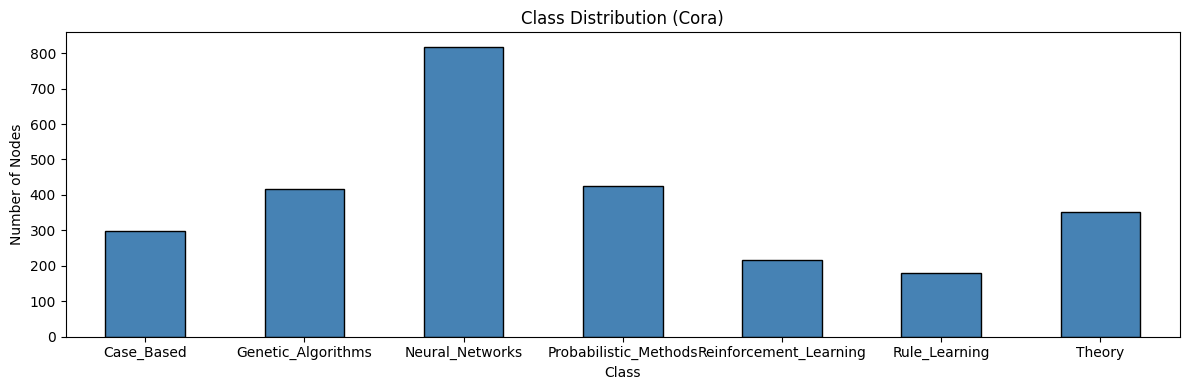

In [6]:
label_counts = node_data['subject'].value_counts().sort_index()

print(label_counts.to_string())
print(f'\nClass balance (min/max ratio): {label_counts.min() / label_counts.max():.2f}')

fig, ax = plt.subplots(figsize=(12, 4))
label_counts.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Class Distribution (Cora)')
ax.set_xlabel('Class')
ax.set_ylabel('Number of Nodes')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


## Data Quality - Missing Values

In [7]:
nan_in_features = torch.isnan(data.x).sum().item()
nan_in_labels = torch.isnan(data.y.float()).sum().item()

print(f'NaN values in node features: {int(nan_in_features)}')
print(f'NaN values in labels:        {int(nan_in_labels)}')


NaN values in node features: 0
NaN values in labels:        0


## Feature Statistics and Sparsity

Cora node features are sparse bag-of-words indicators.

In [8]:
x = data.x.numpy()
total_entries = x.size
nonzero_entries = (x != 0).sum()
sparsity = 1 - nonzero_entries / total_entries

print(f'Feature matrix shape:           {x.shape}')
print(f'Non-zero entries:               {nonzero_entries:,}')
print(f'Sparsity:                       {sparsity:.2%}')
print(f'Avg non-zero features per node: {nonzero_entries / x.shape[0]:.1f}')
print(f'Feature value range:            [{x.min():.4f}, {x.max():.4f}]')
print(f'Feature mean:                   {x.mean():.6f}')
print(f'Feature std:                    {x.std():.6f}')


Feature matrix shape:           (2708, 1433)
Non-zero entries:               49,216
Sparsity:                       98.73%
Avg non-zero features per node: 18.2
Feature value range:            [0.0000, 1.0000]
Feature mean:                   0.012683
Feature std:                    0.111901


## Degree Distribution

Average degree: 3.90
Max degree:     168
Min degree:     1


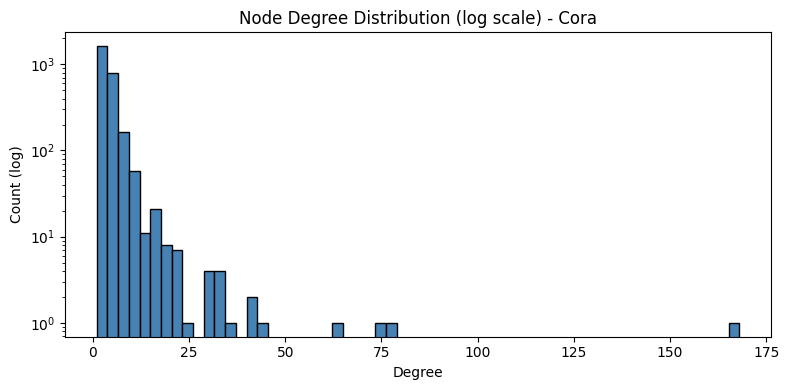

In [9]:
deg = degree(data.edge_index[0], num_nodes=data.num_nodes).numpy()

print(f'Average degree: {deg.mean():.2f}')
print(f'Max degree:     {int(deg.max())}')
print(f'Min degree:     {int(deg.min())}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(deg, bins=60, color='steelblue', edgecolor='black', log=True)
ax.set_title('Node Degree Distribution (log scale) - Cora')
ax.set_xlabel('Degree')
ax.set_ylabel('Count (log)')
plt.tight_layout()
plt.show()


## Graph Connectivity

We evaluate connected components on the undirected graph view.

In [10]:
Gnx = to_networkx(data, to_undirected=True)

components = list(nx.connected_components(Gnx))
sizes = sorted([len(c) for c in components], reverse=True)

print(f'Is connected:              {nx.is_connected(Gnx)}')
print(f'Number of components:      {len(components)}')
print(f'Largest component size:    {sizes[0]:,} nodes  ({sizes[0]/Gnx.number_of_nodes():.1%} of all nodes)')
if len(sizes) > 1:
    print(f'2nd largest component:     {sizes[1]} nodes')
print(f'Isolated nodes (degree=0): {sum(1 for _, d in Gnx.degree() if d == 0)}')


Is connected:              False
Number of components:      78
Largest component size:    2,485 nodes  (91.8% of all nodes)
2nd largest component:     26 nodes
Isolated nodes (degree=0): 0


## Standard Train / Val / Test Split

Cora uses the standard semi-supervised split convention from Yang et al. (2016):
- **Train**: 140 nodes (20 per class x 7 classes)
- **Validation**: 500 nodes
- **Test**: 1,000 nodes

The remaining nodes are unlabelled during training.

In [11]:
n_train = int(data.train_mask.sum())
n_val = int(data.val_mask.sum())
n_test = int(data.test_mask.sum())
n_total = data.num_nodes
n_unlabelled = n_total - n_train - n_val - n_test

print(f'Total nodes:       {n_total:,}')
print(f'Train nodes:       {n_train}  ({n_train/n_total:.1%})')
print(f'Val nodes:         {n_val}   ({n_val/n_total:.1%})')
print(f'Test nodes:        {n_test}  ({n_test/n_total:.1%})')
print(f'Unlabelled (rest): {n_unlabelled:,}  ({n_unlabelled/n_total:.1%})')


Total nodes:       2,708
Train nodes:       140  (5.2%)
Val nodes:         500   (18.5%)
Test nodes:        1000  (36.9%)
Unlabelled (rest): 1,068  (39.4%)


## Embeddings Preview for Both Datasets

We print a compact preview of node feature embeddings (input vectors `x`) for Cora and PubMed.

In [12]:
cols = [f'bag_of_words_{i}' for i in range(data.x.shape[1])]
preview_df = pd.DataFrame(data.x.numpy(), columns=cols)

print(f'Cora embedding matrix shape: {tuple(data.x.shape)}')
preview_df.head()


Cora embedding matrix shape: (2708, 1433)


,bag_of_words_0,bag_of_words_1,bag_of_words_2,bag_of_words_3,bag_of_words_4,bag_of_words_5,bag_of_words_6,bag_of_words_7,bag_of_words_8,bag_of_words_9,...,bag_of_words_1423,bag_of_words_1424,bag_of_words_1425,bag_of_words_1426,bag_of_words_1427,bag_of_words_1428,bag_of_words_1429,bag_of_words_1430,bag_of_words_1431,bag_of_words_1432
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
